# Water-biomass dynamics nonautonomous model

We consider a dynamical system describing the interaction between water $e(t)$ available in the root zone and a given crop (biomass) $z(t)$, under a given water threshold $e_{\max}(t)$:

$$
\begin{cases}
\displaystyle \dot{e}(t) = -\alpha(t) e(t) - \beta(t) e(t)\left(1-\frac{e(t)}{e_{\max}(t)}\right)_{+} z(t) + u(t),\\[2mm]
\displaystyle \dot{z}(t) = -\gamma(t) z(t) + \delta(t) e(t)\left(1-\frac{e(t)}{e_{\max}(t)}\right)_{+} z(t)
\end{cases}
$$

with initial conditions $e(0)=e_{0}$ and $z(0)=z_{0}$ where $(a)_+ := \max(a, 0)$ . 
More precisely:

- $\alpha(t)$ is the water loss coefficient (evaporation, runoff, drainage). 
- $\gamma(t)$ is the natural biomass loss coefficient during growth.
- $\beta(t)$ is the plant water uptake coefficient during growth.
- $\delta(t)$ is the biomass production coefficient associated with water consumption. 
- $e_{max}(t)$ is a water threshold above which the plant ceases to take up water, with a risk of root asphyxia or senescence. Thus,  $\left(1-\frac{e(t)}{e_{\max}(t)}\right)_{+}$ means that if $ e(t) < e_{max}(t)$ then the plant continues to take up water for growth, with an effet
$\beta(t) e(t) \left(1-\frac{e(t)}{e_{max}(t)}\right)z(t)$ on the water state. However, if $ e(t) \geq e_{max}(t)$ then the plant no longer takes up water and therefore $\left(1-\frac{e(t)}{e_{\max}(t)}\right)_{+}=0$. 
- $u(t)$ is the combined input of rainwater and irrigation water.

## 1. Modules importation

Install these packages if they are not installed on the Python distribution.

Uncomment the lignes and run the cell to proced to the installation.

In [1]:
# %pip install numpy
# %pip install matplotlib
# %pip install pandas
# %pip install scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11

## 2. System definition and resolution functions

### 2.1. System definition

In [3]:
def system(t, v, emax, u, alpha, beta, gamma, delta):
    e, z = v
    interaction = e * max(1.0 - e / emax(t), 0.0) * z
    de = -alpha(t) * e - beta(t) * interaction + u(t)
    dz = -gamma(t) * z + delta(t) * interaction
    return np.array([de, dz], dtype=float)

### 2.2. Numerical solver

In [4]:
def simulate(e0, z0, emax, u, alpha, beta, gamma, delta, T, n):
    y0 = (e0, z0)
    t_eval = np.linspace(0.0, T, n)
    sol = solve_ivp(
        fun=lambda t, v : system(t, v, emax, u, alpha, beta, gamma, delta),
        t_span=(0.0, T),
        y0=np.asarray(y0, dtype=float),
        t_eval=t_eval,
        method="RK45",
        rtol=1e-8,
        atol=1e-10,
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

### 2.3. Interaction facteur

In the active region $0<e<e_{\max}(t)$, the interaction can be written as
$$
\mathcal{I}(t,e,z) = g_t(e) z
$$

with 

$$
g_t(e) = e\left(1 - \frac{e}{e_{\max}(t)}\right)
$$

the interaction based on the water stock $e$ only.

For fixed $t$ and $z$, the derivative of $\mathcal{I}(t,e,z)$ reads 

$$
\frac{\partial \mathcal{I}}{\partial e}(t,e,z) = \left(1-\frac{2e}{e_{\max}(t)}\right)z
$$

It reaches its maximum for

$$
e^c=\frac{e_{\max}}{2},
$$

with the value

$$
\mathcal{I}(t, e^c, z) = \frac{e_{\max}^2 z}{4}.
$$

Three regimes are distinguished for the interaction with respect to the water component:

- $0<e<\frac{e_{\max}(t)}{2}$: the interaction intensity increases with $e$;
- $\frac{e_{\max}(t)}{2}<e<e_{\max}(t)$: the interaction intensity decreases with $e$; 
- $e\geq e_{\max}(t)$: the interaction is null.

Howether, the interaction is linear and strictly increasing in $z$ only when $0 < e < e_{\max}(t)$.

In [5]:
def interaction_on_e(t_eval, e):
    inter = []
    for i, t in enumerate(t_eval):
        e_value = e[i]
        inter.append(e_value * np.maximum(1.0 - e_value / emax(t), 0.0))
    return inter

In [6]:
def interaction_global(t_eval, e, z):
    inter = []
    for i, t in enumerate(t_eval):
        e_value = e[i]
        z_value = z[i]
        inter.append(e_value * np.maximum(1.0 - e_value / emax(t), 0.0) * z_value)
    return inter

## 4. Simulation

### 4.1. Model parameters

#### Time horizon

In [7]:
T = 30 * 4 + 10
n = T * 5
t_eval = np.linspace(0.0, T, n)

#### Crop cycle and requirement water

Under arid or semi-arid climatic conditions, FAO (Food and Agriculture Organization of the United Nations) propose for potato, a $130$-day crop cycle divided into for stages : 
 initial stage ($25$ days), 
 development ($30$ days), 
 mid-season ($45$ days), 
 and late season ($30$ days)
. We therefore consider the following stage intervals:

  $$
  [0,25],\quad
  (25,55],\quad
  (55,100],\quad
  (100,130].
  $$

The daily crop water requirement is estimated from the classical relation
$$  
  ET_c(t)=K_c(t)ET_0,
$$

where $ET_0$ denotes the reference evapotranspiration and $K_c(t)$ the crop coefficient.

In [8]:
ET0 = 5.0           # mm/day
tau0 = 1.0          # day
kappa = 0           # dimensionless

In [9]:
def Kc(t):
    if t <= 25:
        return 0.45
    elif t <= 55:
        return 0.45 + (0.70/30.0)*(t-25)
    elif t <= 100:
        return 1.15
    else:
        return 1.15 - (0.30/30.0)*(t-100)

def ETc(t):
    return Kc(t) * ET0

In [10]:
ETc_eval = np.array([ETc(t) for t in t_eval])
print("ETc(0) =", ETc(0), "mm/day")
print("ETc maximum =", ETc_eval.max(), "mm/day")
print("Integrale of ETc ≈", np.trapz(ETc_eval, t_eval), "mm")

ETc(0) = 2.25 mm/day
ETc maximum = 5.75 mm/day
Integrale of ETc ≈ 584.9996141984468 mm


#### Threshold water $e_{\max(t)}$

In [11]:
def emax(t):
    return 2.0 * tau0 * ETc(t)

In [12]:
emax_eval = np.array([emax(t) for t in t_eval])

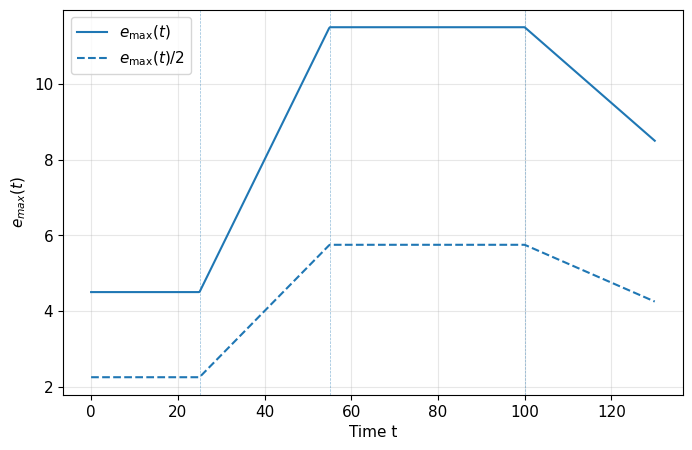

In [13]:
plt.plot(t_eval, emax_eval, label=r'$e_{\max}(t)$')
plt.plot(t_eval, emax_eval/2, label=r'$e_{\max}(t)/2$', linestyle='--', color='tab:blue')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.legend()
plt.xlabel("Time t")
plt.ylabel(r"$e_{max}(t)$")
plt.grid(True, alpha=0.3)
plt.show()

#### Coefficients $\alpha(t), \beta(t), \gamma(t)$ and $\delta(t)$

In [14]:
def alpha(t):
    if t <= 25:
        return 0.20
    elif t <= 55:
        return 0.20 + (0.10 / 30.0) * (t - 25)
    elif t <= 100:
        return 0.30 + (0.10 / 45.0) * (t - 55)
    else:
        return 0.40 - (0.05 / 30.0) * (t - 100)

alpha_eval = np.array([alpha(t) for t in t_eval])

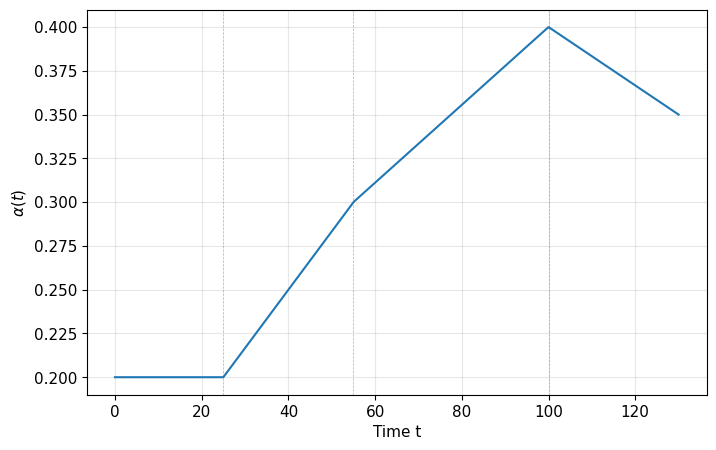

In [15]:
plt.plot(t_eval, alpha_eval)
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t")
plt.ylabel(r"$\alpha(t)$")
plt.grid(True, alpha=0.3)
plt.show()

In [16]:
def beta(t):
    if t <= 25:
        return 0.05 
        # return (0.05 / 25.0) * t
    elif t <= 55:
        return 0.05 + (0.03 / 30.0) * (t - 25)
    elif t <= 100:
        return 0.08 + (0.02 / 45.0) * (t - 55)
    else:
        # return 0.10 - (0.05 / 30.0) * (t - 100)
        return 0.10 - (0.1 / 30.0) * (t - 100)

beta_eval = np.array([beta(t) for t in t_eval])

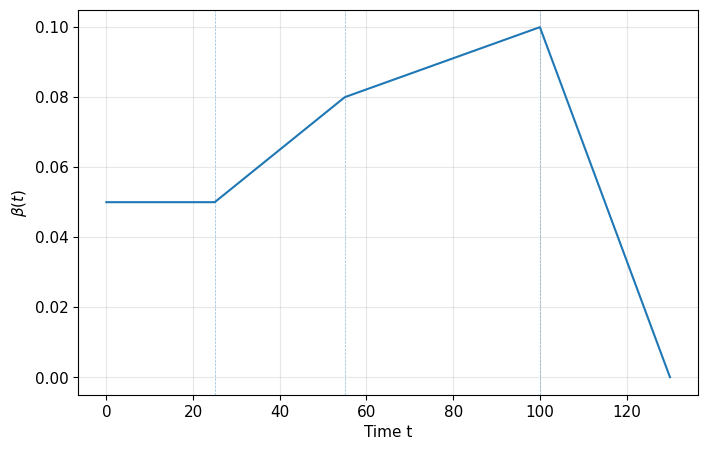

In [17]:
plt.plot(t_eval, beta_eval)
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t")
plt.ylabel(r"$\beta(t)$")
plt.grid(True, alpha=0.3)
plt.show()

In [18]:
def gamma(t):
    if t <= 25:
        return 0.010
        return (0.010 / 25.0) * t
    elif t <= 55:
        return 0.010 + (0.005 / 30.0) * (t - 25)
    elif t <= 100:
        return 0.015 + (0.005 / 45.0) * (t - 55)
    else:
        return 0.020 + (0.060 / 30.0) * (t - 100)

gamma_eval = np.array([gamma(t) for t in t_eval])

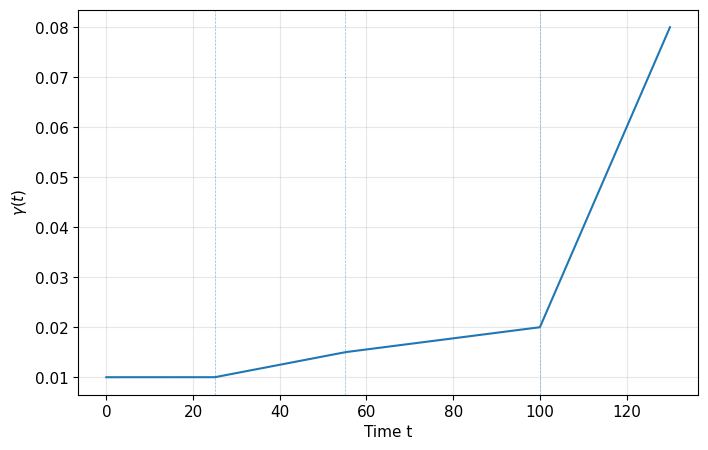

In [19]:
plt.plot(t_eval, gamma_eval)
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t")
plt.ylabel(r"$\gamma(t)$")
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
def delta(t):
    if t <= 25:
        return 0.008
        # return (0.008 / 25.0) * t
    elif t <= 55:
        return 0.008 + (0.004 / 30.0) * (t - 25)
    elif t <= 100:
        return 0.012 + (0.003 / 45.0) * (t - 55)
    else:
        # return 0.015 - (0.012 / 30.0) * (t - 100)
        return 0.015 - (0.015 / 30.0) * (t - 100)

delta_eval = np.array([delta(t) for t in t_eval])

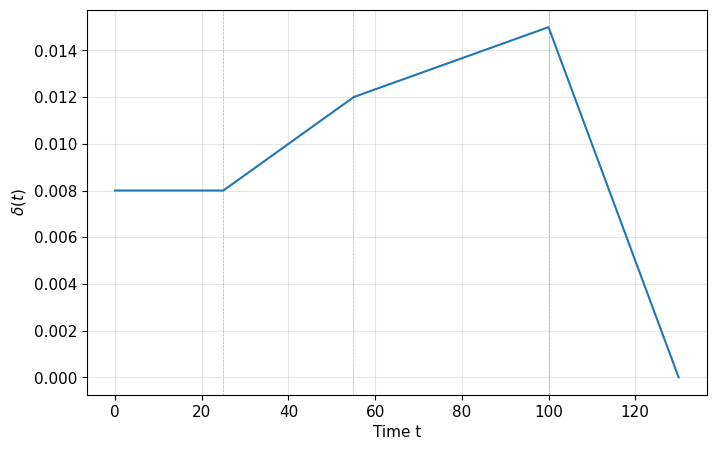

In [21]:
plt.plot(t_eval, delta_eval)
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t")
plt.ylabel(r"$\delta(t)$")
plt.grid(True, alpha=0.3)
plt.show()

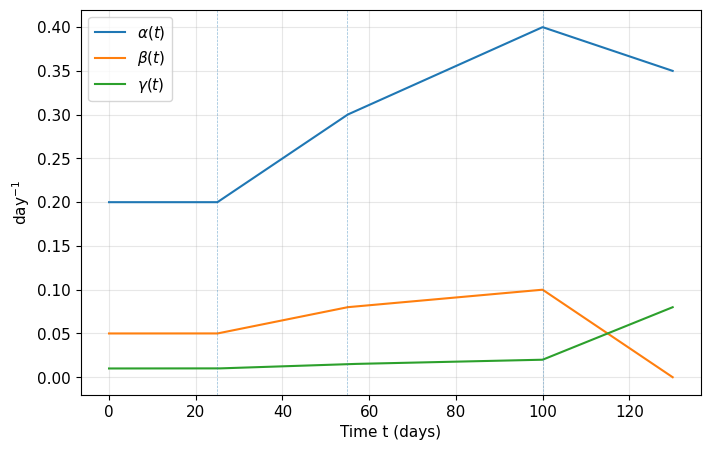

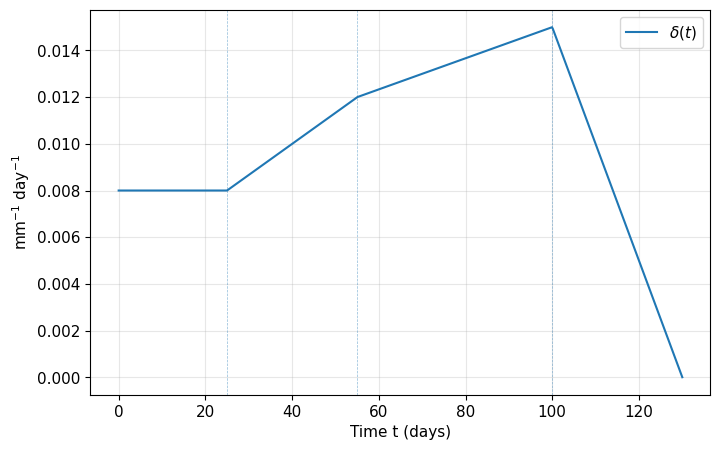

In [22]:
# plt.figure(figsize=(8, 4.8))
plt.plot(t_eval, alpha_eval, label=r"$\alpha(t)$")
plt.plot(t_eval, beta_eval, label=r"$\beta(t)$")
plt.plot(t_eval, gamma_eval, label=r"$\gamma(t)$")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"day$^{-1}$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# plt.figure(figsize=(8, 4.8))
plt.plot(t_eval, delta_eval, label=r"$\delta(t)$")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"mm$^{-1}$ day$^{-1}$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Water input $u(t)$

In [23]:
def Peff(t):
    if t <= 25:
        P = 25.0
    elif t <= 55:
        P = 50.0
    elif t <= 100:
        P = 100.0
    else:
        P = 50.0

    if P < 75:
        return max(0.6 * P - 10, 0.0) / 30.0
    else:
        return max(0.8 * P - 25, 0.0) / 30.0

def Irrigation(t):
    return kappa * max(emax(t)/2 - Peff(t), 0.0)

def u(t):
    return Peff(t) + Irrigation(t)

In [24]:
Peff_eval = np.array([Peff(t) for t in t_eval])
Irrigation_eval = np.array([Irrigation(t) for t in t_eval])
u_eval = np.array([u(t) for t in t_eval])

In [25]:
print("Cumulative efficace rainfall ≈", np.trapz(Peff_eval, t_eval), "mm")
print("Cumulative irrigation ≈", np.trapz(Irrigation_eval, t_eval), "mm")
print("Cumulative input water ≈", np.trapz(u_eval, t_eval), "mm")

Cumulative efficace rainfall ≈ 126.77837699024138 mm
Cumulative irrigation ≈ 0.0 mm
Cumulative input water ≈ 126.77837699024138 mm


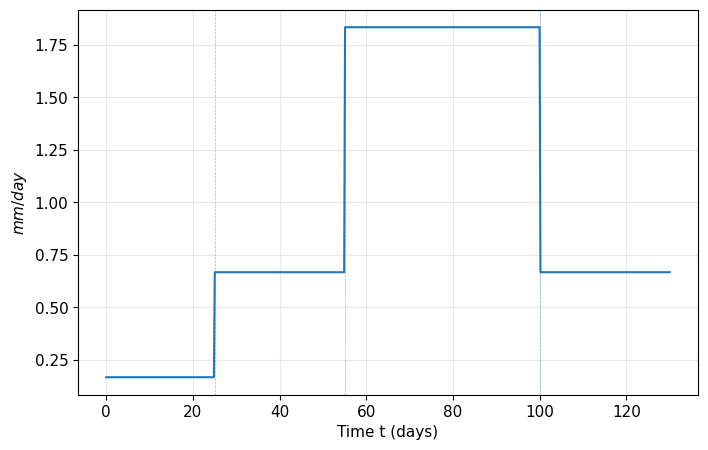

In [26]:
plt.plot(t_eval, u_eval)
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$mm/day$")
plt.grid(True, alpha=0.3)
plt.show()

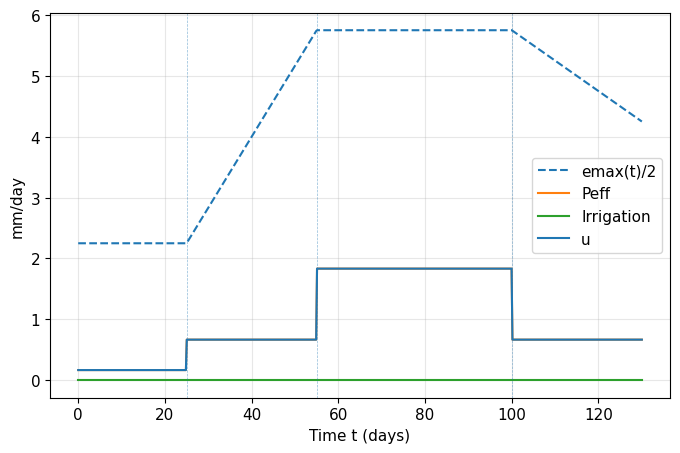

In [27]:
plt.plot(t_eval, emax_eval/2, "--", label="emax(t)/2")
plt.plot(t_eval, Peff_eval, label="Peff")
plt.plot(t_eval, Irrigation_eval, label="Irrigation")
plt.plot(t_eval, u_eval, label="u", color='tab:blue')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel("mm/day")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

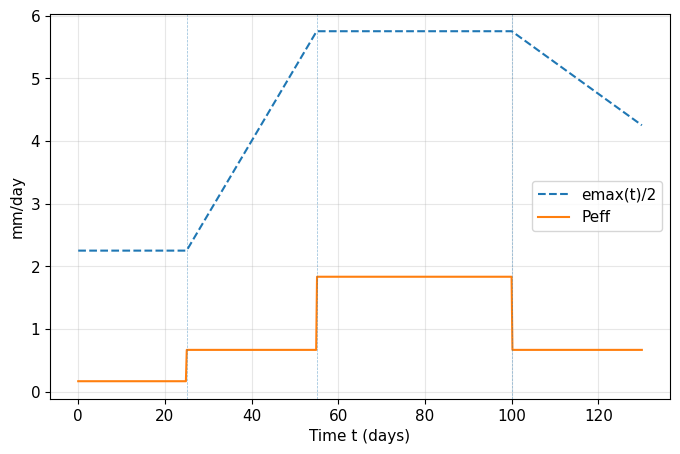

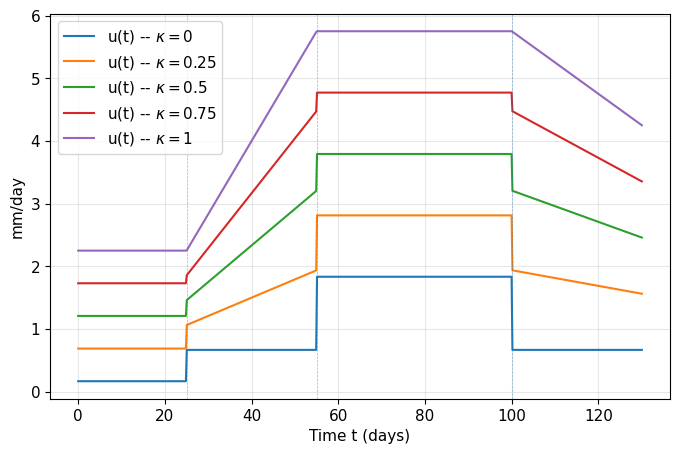

In [28]:
plt.plot(t_eval, emax_eval/2, "--", label="emax(t)/2")
plt.plot(t_eval, Peff_eval, label="Peff")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel("mm/day")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

for k in [0, 0.25, 0.5, 0.75, 1]:
    kappa = k
    u_eval = np.array([u(t) for t in t_eval])
    plt.plot(t_eval, u_eval, label=rf"u(t) -- $\kappa={kappa}$")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)

plt.xlabel("Time t (days)")
plt.ylabel("mm/day")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

kappa = 0 # in order to comeback to no irrigation profil

#### Referential initial conditions

In [29]:
e0_ref = tau0 * ETc(0.0)
z0_ref = 0.1

### 4.2. Resolution

In [30]:
sol = simulate(e0_ref, z0_ref, emax, u, alpha, beta, gamma, delta, T, n)

In [31]:
print("emax =", sol.y[0].max(), 'mm')
print("t_emax =", t_eval[np.argmax(sol.y[0])])
print("e_final =", sol.y[0][-1], 'mm')
print("zmax =", sol.y[1].max())
print("t_zmax =", t_eval[np.argmax(sol.y[1])])
print("z_final =", sol.y[1][-1])

interaction_active = np.mean((sol.y[0] > 0) & (sol.y[0] < emax_eval)) * 100.0
print("Percentage of active interaction =", interaction_active)

emax = 5.5623845059823545 mm
t_emax = 65.90138674884437
e_final = 1.875118131040035 mm
zmax = 0.2664331191091316
t_zmax = 102.95839753466872
z_final = 0.08364119309110518
Percentage of active interaction = 100.0


### 4.3. Evolution of e & z

#### Comparative time evolution of $e(.)$ and $z(.)$

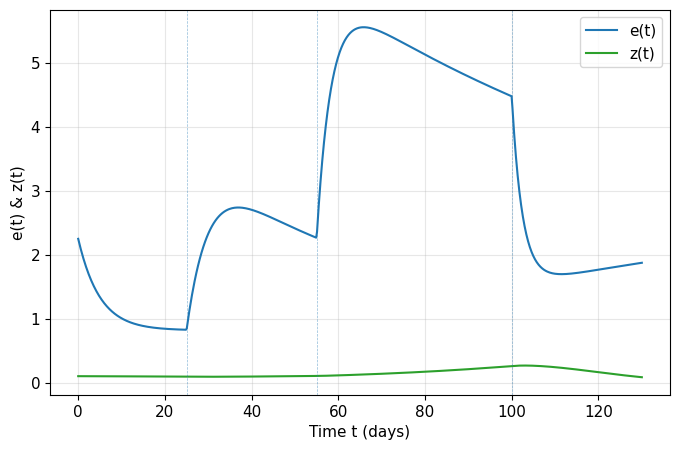

In [32]:
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
plt.plot(sol.t, sol.y[1], label="z(t)", color='tab:green')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel("e(t) & z(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

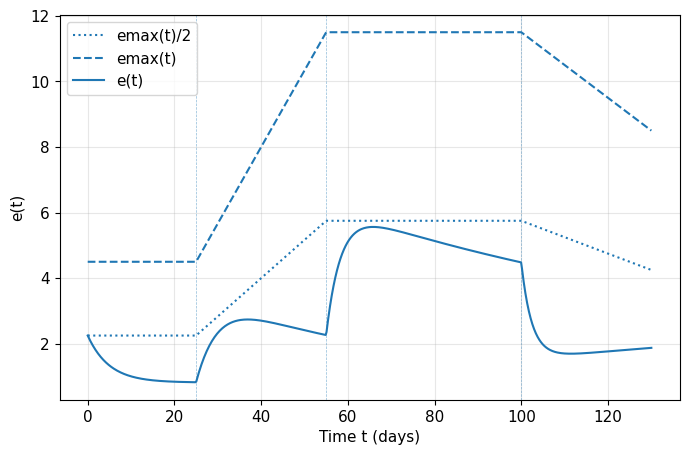

In [33]:
plt.plot(t_eval, emax_eval/2, ":", label="emax(t)/2", color='tab:blue')
plt.plot(t_eval, emax_eval, "--", label="emax(t)", color='tab:blue')
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel("e(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

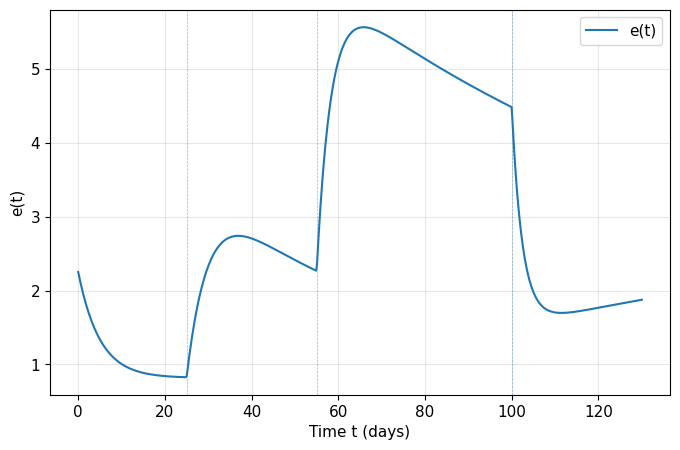

In [34]:
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel("e(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

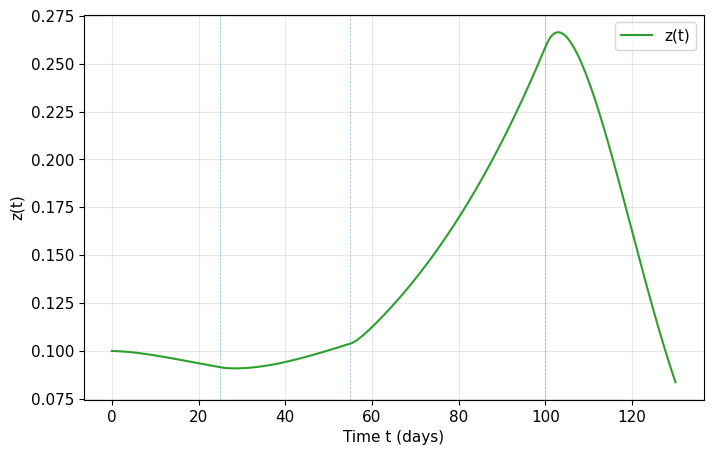

In [35]:
plt.plot(sol.t, sol.y[1], label="z(t)", color='tab:green')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel("z(t)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Evolution of the interaction with comparison to $e(.)$ and $z(.)$

In [36]:
interaction_values = interaction_on_e(t_eval, sol.y[0])
g_interaction_values = interaction_global(t_eval, sol.y[0], sol.y[1])

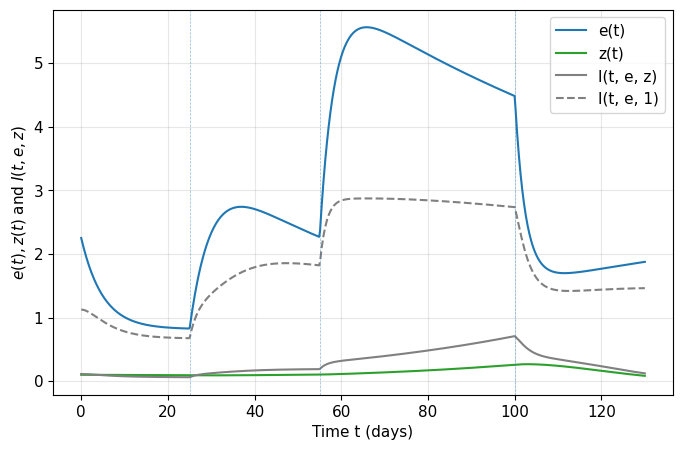

In [37]:
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
plt.plot(sol.t, sol.y[1], label="z(t)", color='tab:green')
plt.plot(t_eval, g_interaction_values, label='I(t, e, z)', color='gray')
plt.plot(t_eval, interaction_values, label='I(t, e, 1)', linestyle="--", color='gray')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$e(t), z(t)$ and $I(t, e, z)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

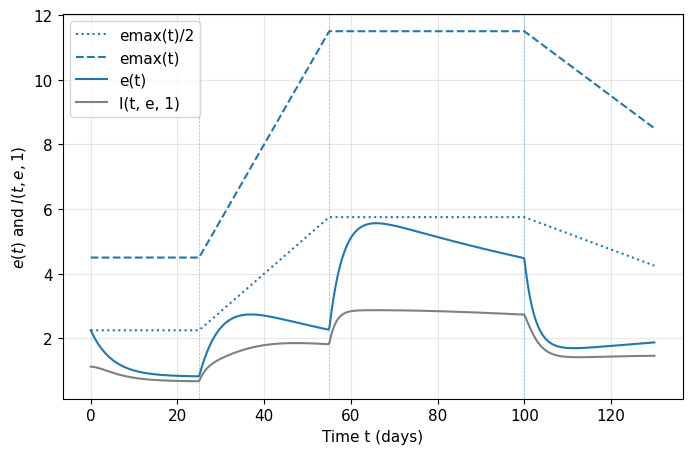

In [38]:
plt.plot(t_eval, emax_eval/2, ":", label="emax(t)/2", color='tab:blue')
plt.plot(t_eval, emax_eval, "--", label="emax(t)", color='tab:blue')
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
plt.plot(t_eval, interaction_values, label='I(t, e, 1)', linestyle="-", color='gray')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$e(t)$ and $I(t, e, 1)$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

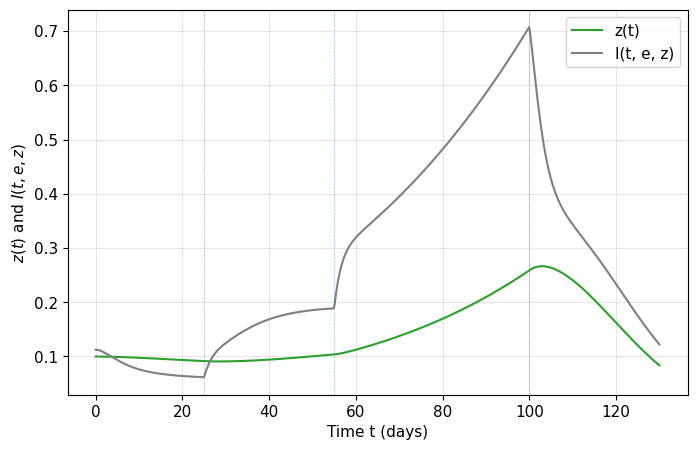

In [39]:
plt.plot(sol.t, sol.y[1], label="z(t)", color='tab:green')
plt.plot(t_eval, g_interaction_values, label='I(t, e, z)', color='gray')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$z(t)$ and $I(t, e, z)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

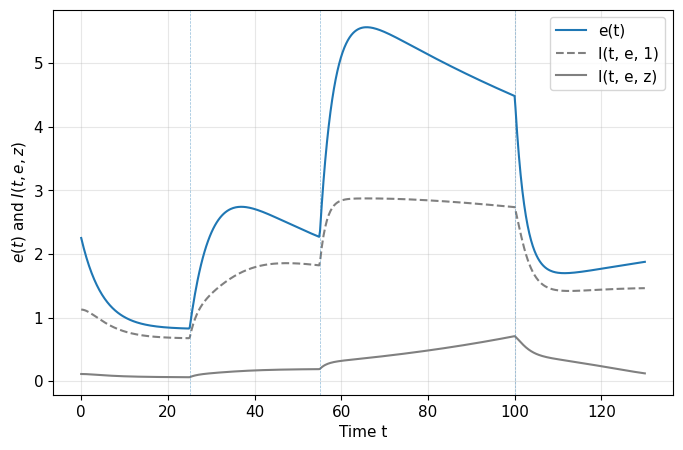

In [40]:
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
plt.plot(t_eval, interaction_values, label='I(t, e, 1)', linestyle="--", color='gray')
plt.plot(t_eval, g_interaction_values, label='I(t, e, z)', color='gray', linestyle="-")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t")
plt.ylabel(r"$e(t)$ and $I(t, e, z)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

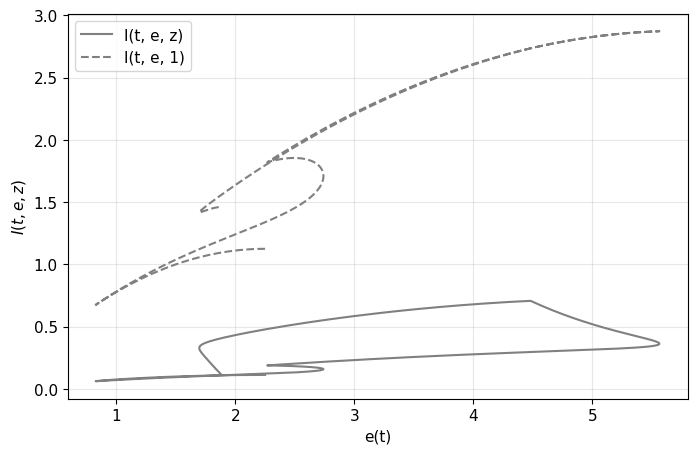

In [41]:
plt.plot(sol.y[0], g_interaction_values, label='I(t, e, z)', color='gray')
plt.plot(sol.y[0], interaction_values, label='I(t, e, 1)', color='gray', linestyle='--')
plt.xlabel("e(t)")
plt.ylabel(r"$I(t, e, z)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

#### Portrait des phases $(e, z)$

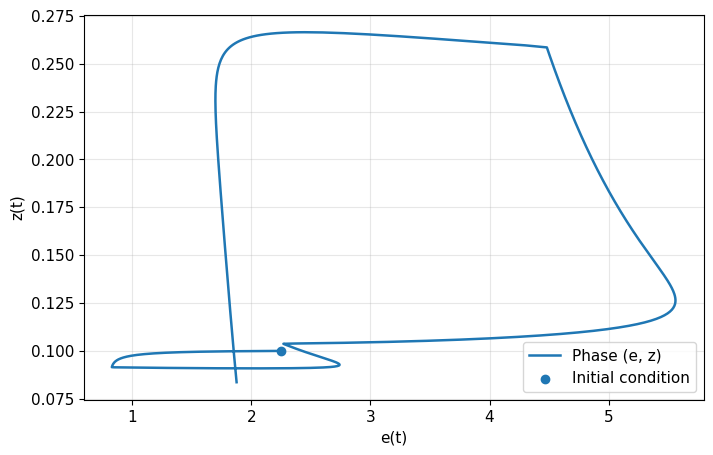

In [42]:
plt.plot(sol.y[0], sol.y[1], linewidth=1.8, label="Phase (e, z)")
plt.scatter([e0_ref], [z0_ref], label="Initial condition", zorder=3)
plt.xlabel("e(t)")
plt.ylabel("z(t)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 4.4. Input water sensibility

#### Variation of $\kappa$

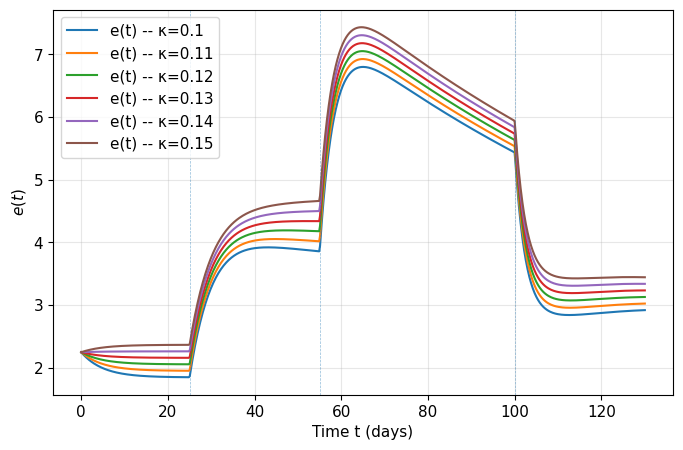

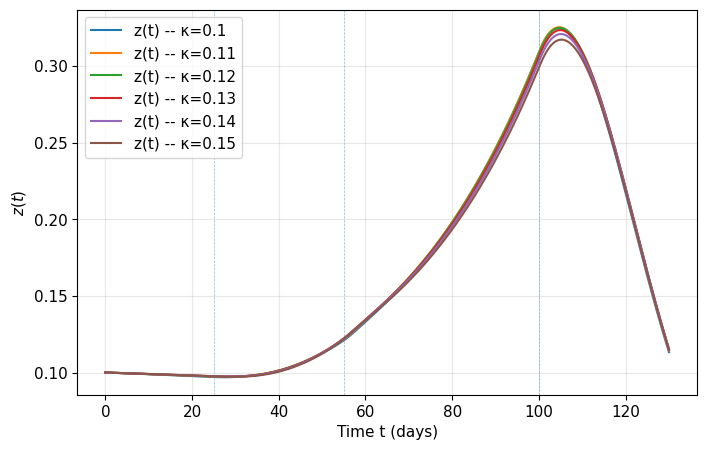

In [43]:
# kappa_eval = [0, 0.25, 0.5, 0.75, 1.0]
kappa_eval = [0.1, 0.11, 0.12, 0.13, 0.14, 0.15]
results = []

for k in kappa_eval:
    kappa = k
    sol = simulate(e0_ref, z0_ref, emax, u, alpha, beta, gamma, delta, T, n)
    results.append(sol)

for i, sol in enumerate(results):
    plt.plot(sol.t, sol.y[0], label=f"e(t) -- κ={kappa_eval[i]}")
# plt.plot(t_eval, emax_eval/2, ":", label="emax(t)/2", color='tab:blue')
# plt.plot(t_eval, emax_eval, "--", label="emax(t)", color='tab:blue')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$e(t)$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

for i, sol in enumerate(results):
    plt.plot(sol.t, sol.y[1], label=f"z(t) -- κ={kappa_eval[i]}")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$z(t)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

In [44]:
kappa_eval = np.round(np.arange(0.0, 0.5, 0.01), 2)
results = []

for k in kappa_eval:
    kappa = k
    s = simulate(e0_ref, z0_ref, emax, u, alpha, beta, gamma, delta, T, n)
    results.append({
        "kappa": k,
        "zmax": s.y[1].max(),
        "t_zmax": t_eval[np.argmax(s.y[1])],
        "z_final": s.y[1][-1],
        "e_max": s.y[0].max(),
        "e_final": s.y[0][-1],
        "active_percent": np.mean((s.y[0] > 0) & (s.y[0] < emax_eval)) * 100.0,
        "irrigation_cumulee": np.trapz([Irrigation(t) for t in t_eval], t_eval),
        "u_cumulee": np.trapz([u(t) for t in t_eval], t_eval)
    })
    
summary = pd.DataFrame({
    "kappa": kappa_eval,
    "z_max": [r["zmax"] for r in results],
    "t_zmax": [r["t_zmax"] for r in results],
    "z_final": [r["z_final"] for r in results],
    "e_max": [r["e_max"] for r in results],
    "e_final": [r["e_final"] for r in results],
    "interaction_active_%": [r["active_percent"] for r in results],
    "irrigation_cumulee_mm": [r["irrigation_cumulee"] for r in results],
    "u_cummulee_mm": [r["u_cumulee"] for r in results]
})

kappa_opt_zmax = summary.loc[summary["z_max"].idxmax(), "kappa"]
kappa_opt_zfinal = summary.loc[summary["z_final"].idxmax(), "kappa"]

print("kappa optimisant z_max =", kappa_opt_zmax)
print("kappa optimisant z(130) =", kappa_opt_zfinal)

summary.head()

kappa optimisant z_max = 0.11
kappa optimisant z(130) = 0.13


,kappa,z_max,t_zmax,z_final,e_max,e_final,interaction_active_%,irrigation_cumulee_mm,u_cummulee_mm
0,0.00,0.266433,102.958398,0.083641,5.562385,1.875118,100.0,0.000000,126.778377
1,0.01,0.275586,103.158706,0.087652,5.684391,1.979640,100.0,4.582212,131.360589
2,0.02,0.284180,103.158706,0.091522,5.806678,2.084161,100.0,9.164425,135.942802
3,0.03,0.292150,103.359014,0.095216,5.929302,2.188685,100.0,13.746637,140.525014
4,0.04,0.299410,103.559322,0.098699,6.052310,2.293216,100.0,18.328849,145.107226


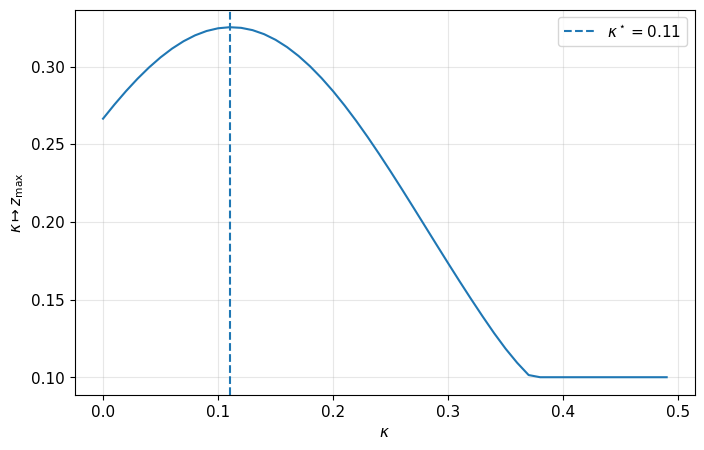

In [45]:
plt.plot(summary["kappa"], summary["z_max"])
plt.axvline(kappa_opt_zmax, linestyle="--",
            label=rf"$\kappa^\star={kappa_opt_zmax:.2f}$")
plt.xlabel(r"$\kappa$")
plt.ylabel(r"$\kappa \mapsto z_{\max}$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

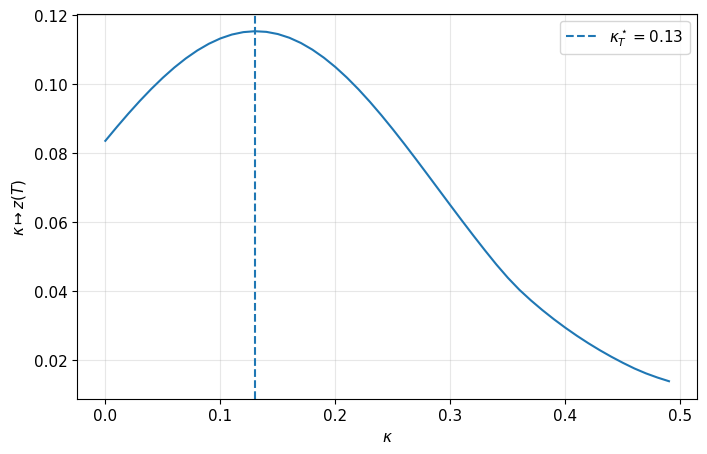

In [46]:
plt.plot(summary["kappa"], summary["z_final"])
plt.axvline(kappa_opt_zfinal, linestyle="--",
            label=rf"$\kappa^\star_{{T}}={kappa_opt_zfinal:.2f}$")
plt.xlabel(r"$\kappa$")
plt.ylabel(r"$\kappa \mapsto z(T)$")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

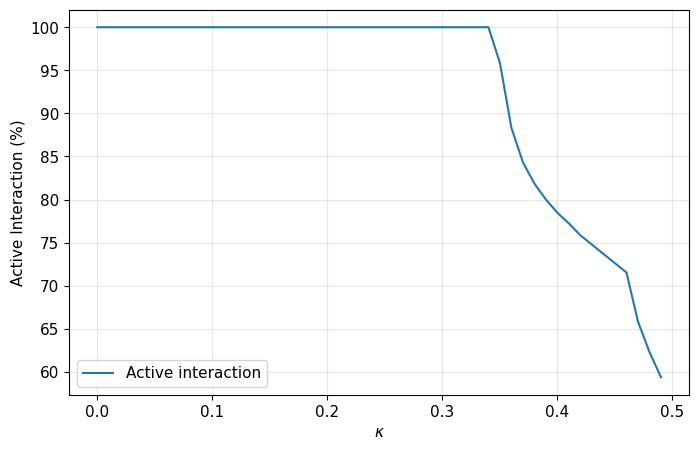

In [47]:
plt.plot(summary["kappa"], summary["interaction_active_%"], label="Active interaction")
plt.xlabel(r"$\kappa$")
plt.ylabel("Active Interaction (%)")
# plt.ylim(-2, 102)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

#### Scenario for $\kappa=\kappa^*$

In [48]:
kappa = kappa_opt_zmax

sol = simulate(e0_ref, z0_ref, emax, u, alpha, beta, gamma, delta, T, n)

reference_summary = pd.DataFrame({
    "Grandeur": [
        "kappa",
        "z_max",
        "jour du maximum de z",
        "z_final",
        "max e(t) [mm]",
        "e_final [mm]",
        "interaction active [%]",
        "irrigation cumulée [mm]",
        "apport total cumulé [mm]"
    ],
    "Valeur": [
        kappa,
        sol.y[1].max(),
        t_eval[np.argmax(sol.y[1])],
        sol.y[1][-1],
        sol.y[0].max(),
        sol.y[0][-1],
        np.mean((sol.y[0] > 0) & (sol.y[0] < emax_eval)) * 100.0,
        np.trapz([Irrigation(t) for t in t_eval], t_eval),
        np.trapz([u(t) for t in t_eval], t_eval)
    ]
})

reference_summary

,Grandeur,Valeur
0,kappa,0.110000
1,z_max,0.325296
2,jour du maximum de z,104.560863
3,z_final,0.114450
4,max e(t) [mm],6.924097
5,e_final [mm],3.025534
6,interaction active [%],100.000000
7,irrigation cumulée [mm],50.404336
8,apport total cumulé [mm],177.182713


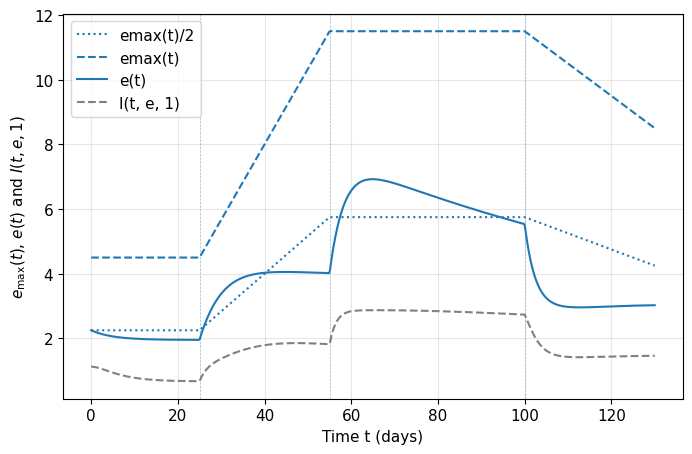

In [49]:
plt.plot(t_eval, emax_eval/2, ":", label="emax(t)/2", color='tab:blue')
plt.plot(t_eval, emax_eval, "--", label="emax(t)", color='tab:blue')
plt.plot(sol.t, sol.y[0], label="e(t)", color='tab:blue')
plt.plot(t_eval, interaction_values, label='I(t, e, 1)', linestyle="--", color='gray')
# plt.plot(t_eval, g_interaction_values, label='I(t, e, z)', color='gray', linestyle="-")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$e_{\max}(t)$, $e(t)$ and $I(t, e, 1)$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

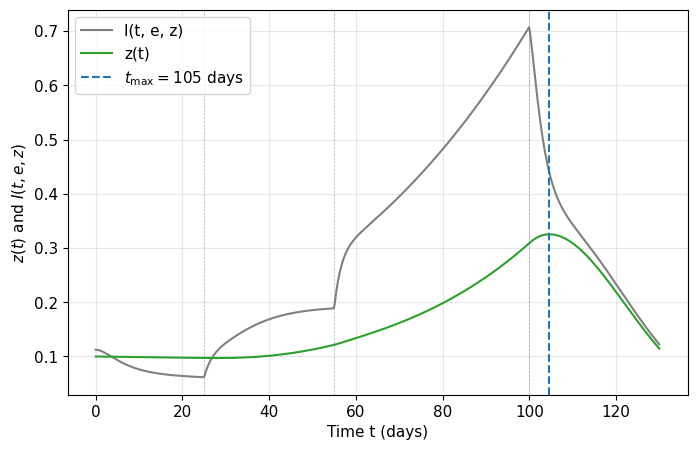

In [50]:
# plt.plot(t_eval, interaction_values, label='Interaction I(t, e, 1)', color='gray', linestyle="--")
plt.plot(t_eval, g_interaction_values, label='I(t, e, z)', color='gray')
plt.plot(sol.t, sol.y[1], label="z(t)", color='tab:green')
plt.axvline(t_eval[np.argmax(sol.y[1])], linestyle="--",
            label=rf"$t_{{\max}}={t_eval[np.argmax(sol.y[1])]:.0f}$ days")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$z(t)$ and $I(t, e, z)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

### 4.5. Sensibility to the initial condition

Having selected $\kappa^\star=0.11$, we examine the robustness of the dynamics with respect to the initial conditions
$$
(e_0,z_0).
$$

The reference scenario is
$$
e_0=2.25\ {\rm mm},\qquad z_0=0.10.
$$

Three analyses are performed:

1. mutual variation of $e_0$ and $z_0$;
2. variation of $z_0$ with $e_0$ fixed;
3. variation of $e_0$ with $z_0$ fixed.

The study is then complemented by a two-dimensional map of $z_{\max}$ as a function of $(e_0,z_0)$.

#### Mutual sensibility with $\kappa=\kappa^*$

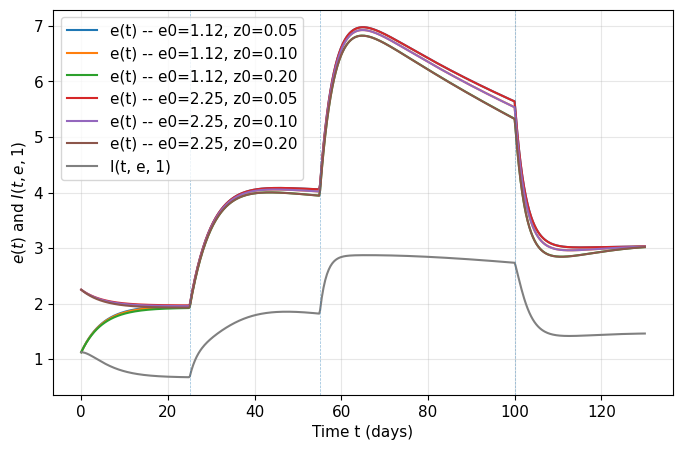

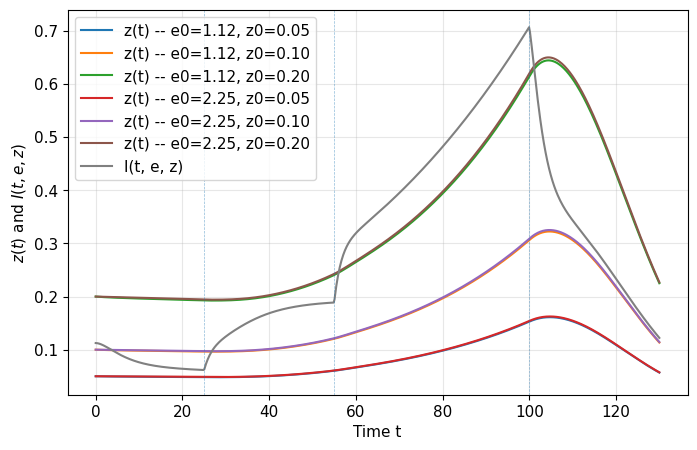

In [51]:
kappa = kappa_opt_zmax

initial_conditions = [
    (e0_ref/2, z0_ref/2), 
    (e0_ref/2, z0_ref), 
    (e0_ref/2, z0_ref*2), 
    (e0_ref, z0_ref/2), 
    (e0_ref, z0_ref),
    (e0_ref, z0_ref*2), 
    # (e0_ref*2, z0/2), 
    # (e0_ref*2, z0),
    # (e0_ref*2, z0*2),
]
results = []

for y0 in initial_conditions:
    sol = simulate(y0[0], y0[1], emax, u, alpha, beta, gamma, delta, T, n)
    results.append(sol)

# plt.plot(t_eval, emax_eval/2, ":", label="emax(t)/2", color='tab:blue')
# plt.plot(t_eval, emax_eval, "--", label="emax(t)", color='tab:blue')
for i, sol in enumerate(results):
    plt.plot(sol.t, sol.y[0], label=f"e(t) -- e0={initial_conditions[i][0]:.2f}, z0={initial_conditions[i][1]:.2f}")
plt.plot(t_eval, interaction_values, label='I(t, e, 1)', linestyle="-", color='gray')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$e(t)$ and $I(t, e, 1)$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

for i, sol in enumerate(results):
    plt.plot(sol.t, sol.y[1], label=f"z(t) -- e0={initial_conditions[i][0]:.2f}, z0={initial_conditions[i][1]:.2f}")
plt.plot(t_eval, g_interaction_values, label='I(t, e, z)', color='gray')
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.5, alpha=0.5)
plt.xlabel("Time t")
plt.ylabel(r"$z(t)$ and $I(t, e, z)$")
plt.legend(loc='best')
plt.grid(True, alpha=0.3)
plt.show()

#### Sensibility by fixing $e_0$ and varying $z_0$

In [52]:
e0_ref = 2.25
kappa = kappa_opt_zmax

# Variations of ±50 % arround z0_ref
z0_values = np.array([0.05, 0.075, 0.10, 0.125, 0.15])

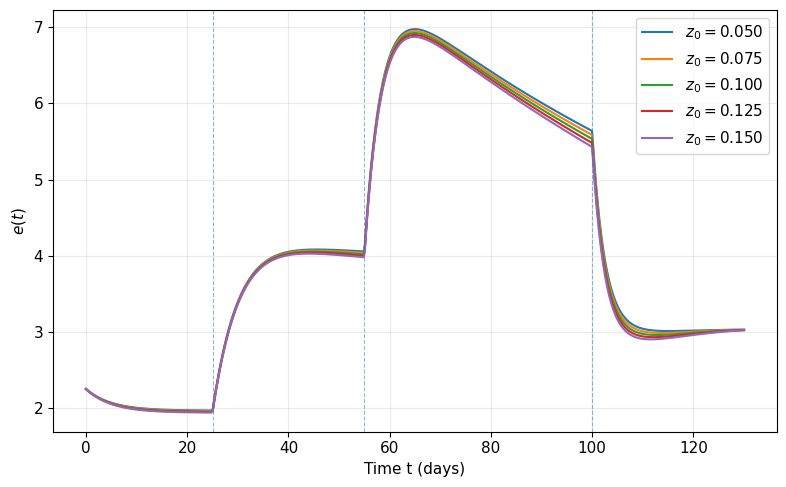

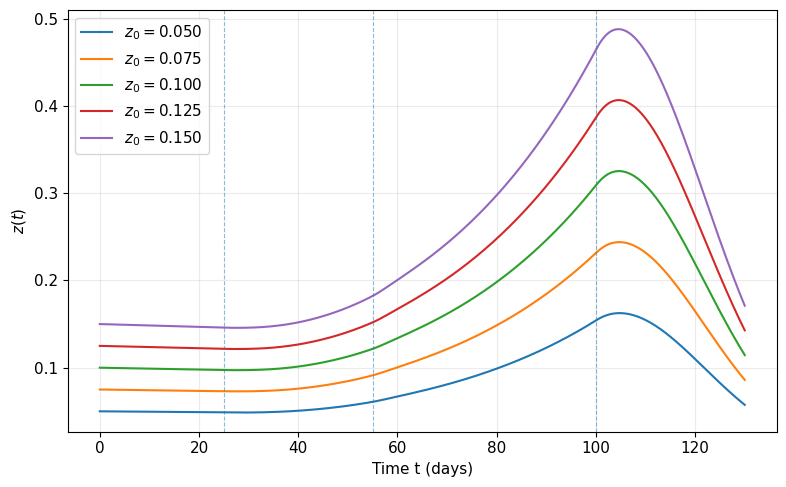

In [53]:
results = []
for z0_i in z0_values:
    sol = simulate(e0_ref, z0_i, emax, u, alpha, beta, gamma, delta, T, n)
    results.append(sol)

for i, sol in enumerate(results):    
    plt.plot(sol.t, sol.y[0], label=fr"$z_0={z0_values[i]:.3f}$")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.8, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$e(t)$")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

for i, sol in enumerate(results): 
    plt.plot(sol.t, sol.y[1], label=fr"$z_0={z0_values[i]:.3f}$")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.8, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$z(t)$")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

#### Sensibility by fixing $z_0$ and varying $e_0$

In [54]:
z0_ref = 0.10
kappa = kappa_opt_zmax

# Variations of ±50 % arround e0_ref
e0_values = np.array([1.125, 1.6875, 2.25, 2.8125, 3.375])

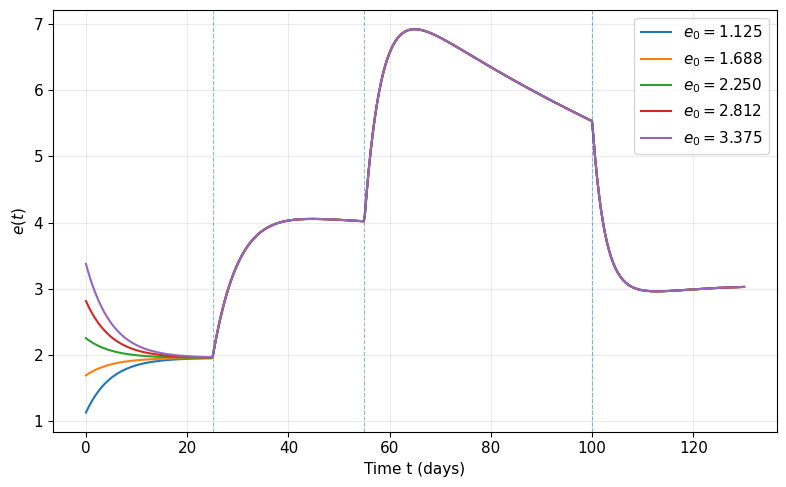

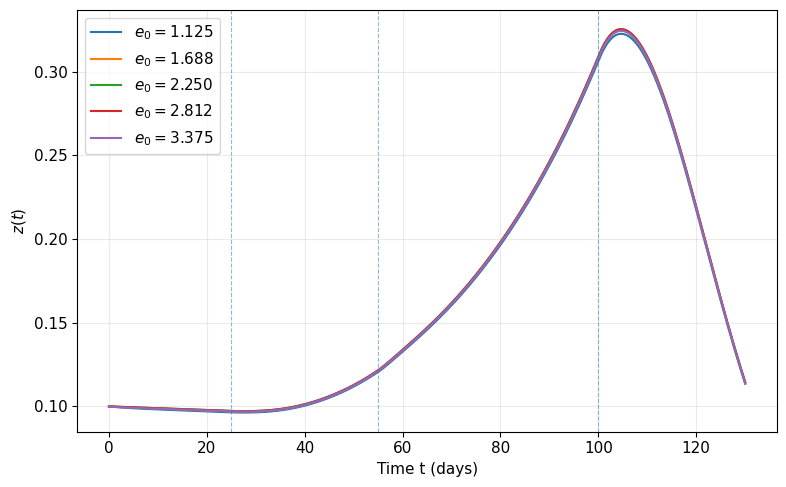

In [55]:
results = []
for e0_i in e0_values:
    sol = simulate(e0_i, z0_ref, emax, u, alpha, beta, gamma, delta, T, n)
    results.append(sol)

for i, sol in enumerate(results):
    plt.plot(sol.t, sol.y[0], label=fr"$e_0={e0_values[i]:.3f}$")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.8, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$e(t)$")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

for i, sol in enumerate(results):
    plt.plot(sol.t, sol.y[1], label=fr"$e_0={e0_values[i]:.3f}$")
for xphase in [25, 55, 100]:
    plt.axvline(xphase, ls="--", lw=0.8, alpha=0.5)
plt.xlabel("Time t (days)")
plt.ylabel(r"$z(t)$")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

#### Map of sensibility of $z_{\max}$ to the initial conditions

This representation makes it possible to visually identify the initial condition that most strongly influences the maximum biomass level.

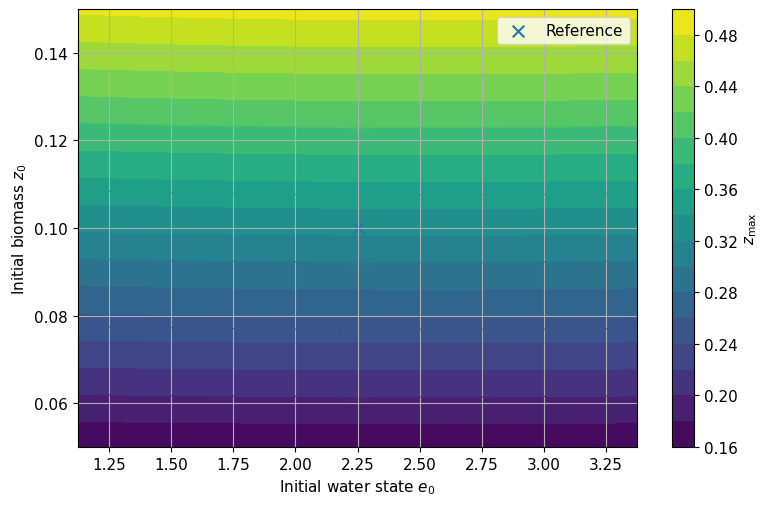

In [56]:
e0_grid = np.linspace(0.5*e0_ref, 1.5*e0_ref, 25)
z0_grid = np.linspace(0.5*z0_ref, 1.5*z0_ref, 25)

ZMAX = np.empty((len(z0_grid), len(e0_grid)))

for j, z0_i in enumerate(z0_grid):
    for i, e0_i in enumerate(e0_grid):
        sol = simulate(e0_i, z0_i, emax, u, alpha, beta, gamma, delta, T, n)
        ZMAX[j, i] = sol.y[1].max()

E0, Z0 = np.meshgrid(e0_grid, z0_grid)

plt.figure(figsize=(8, 5.2))
cf = plt.contourf(E0, Z0, ZMAX, levels=16)
cs = plt.contour(E0, Z0, ZMAX, levels=7, linewidths=0.8)
plt.clabel(cs, fmt="%.3f", fontsize=8)
plt.scatter([e0_ref], [z0_ref], marker="x", s=70, label="Reference")
plt.colorbar(cf, label=r"$z_{\max}$")
plt.xlabel(r"Initial water state $e_0$")
plt.ylabel(r"Initial biomass $z_0$")
plt.legend()
plt.tight_layout()
plt.show()